In [2]:
import pandas as pd
import numpy as np
import astropy.units as u
import setigen as stg
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('curved_planets.xls')
df

,pl_name,pl_orbper,pl_orbsmax,pl_orbper_hr,rmse_hz
0,PSR J1719-1438 b,0.090706,0.004400,2.176951,1851.091183
1,TOI-2431 b,0.224196,0.006300,5.380699,71.228657
2,KOI-55 b,0.240104,0.006000,5.762496,51.571549
3,K2-141 b,0.280324,0.007470,6.727786,34.561497
4,TOI-4552 b,0.301100,0.005626,7.226408,19.554804
5,PSR J2322-2650 b,0.322964,0.010200,7.751136,26.787943
6,KOI-55 c,0.342887,0.007600,8.229288,15.710101
7,TOI-2260 b,0.352473,0.009700,8.459347,17.957447
8,Kepler-78 b,0.355007,0.009010,8.520179,16.208831
9,K2-157 b,0.365258,0.009620,8.766180,15.444038


In [3]:
planet = df.iloc[0]
print(f"Simulating signal for: {planet['pl_name']}")
print(f"Orbital Period (hours): {planet['pl_orbper_hr']}")

Simulating signal for: PSR J1719-1438 b
Orbital Period (hours): 2.176951032


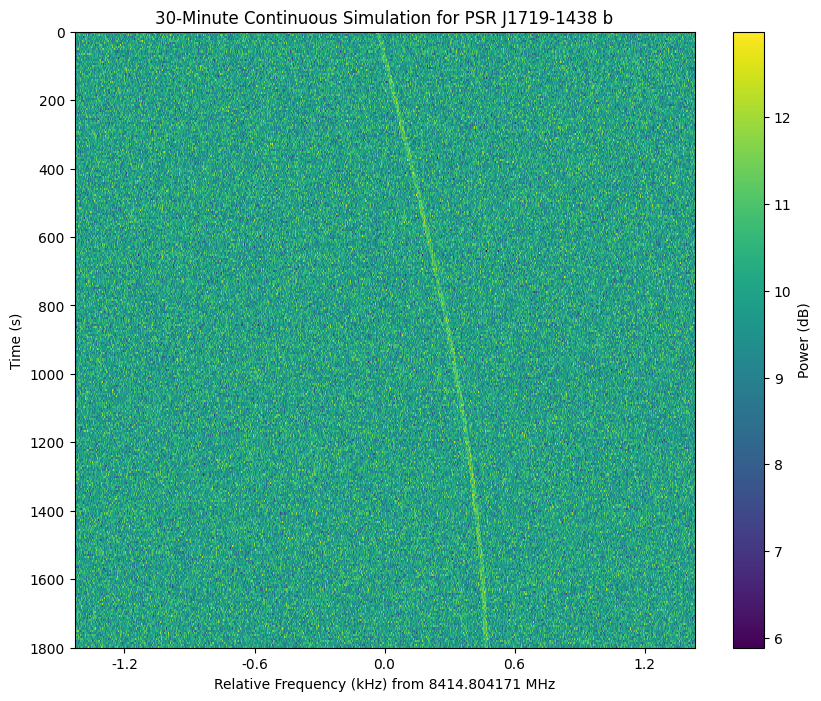

In [4]:
total_obs_time = 30 * 60
tchans_count = 300
dt_step = total_obs_time / tchans_count

frame = stg.Frame(
    fchans=1024,
    tchans=tchans_count,
    df=2.7939677238464355 * u.Hz,
    dt=dt_step * u.s,
    fch1=8414.8056 * u.MHz
)

noise = frame.add_noise(x_mean=10, x_std=1)
period_seconds = planet['pl_orbper_hr'] * 3600

signal_path = stg.sine_path(
    f_start=frame.get_frequency(index=500),
    drift_rate=0.0,
    period=period_seconds,
    amplitude=500.0 * u.Hz
)

frame.add_signal(
    signal_path,
    t_profile=stg.constant_t_profile(level=frame.get_intensity(snr=25)),
    f_profile=stg.box_f_profile(width=20 * u.Hz),
    bp_profile=stg.constant_bp_profile(level=1)
)

%matplotlib inline
fig = plt.figure(figsize=(10, 8))
frame.plot(db=True)
plt.title(f"30-Minute Continuous Simulation for {planet['pl_name']}")
plt.show()

blimpy.waterfall INFO     __write_to_fil_light: Writing the spectra matrix for /tmp/tmpa_oslf0n/synthetic_sim_0.fil in one go.
blimpy.waterfall INFO     Conversion time: 0.03sec

turbo_seti version 2.3.2
blimpy version 2.1.4
h5py version 3.16.0
hdf5plugin version 7.1.0
HDF5 library version 2.0.0


data_handler    INFO     Filterbank file detected. Attempting to create .h5 file in current directory...
blimpy.waterfall INFO     Detecting high frequency resolution data.
blimpy.waterfall INFO     __write_to_hdf5_heavy: For /tmp/tmpa_oslf0n/synthetic_sim_0.h5, chunk_dim=(1, 1, 16384), blob_dim=(300, 1, 16384), n_blobs=1
hdf5plugin._filters WARNING  Deprecation: hdf5plugin.Bitshuffle's lz4 argument is deprecated, use cname='lz4' or 'none' instead.
hdf5plugin._filters WARNING  Deprecation: hdf5plugin.Bitshuffle's lz4 argument is deprecated, use cname='lz4' or 'none' instead.
blimpy.waterfall INFO     __write_to_hdf5_heavy: Processing blob 1 of 1
data_handler    INFO     From user, n_coarse_ch

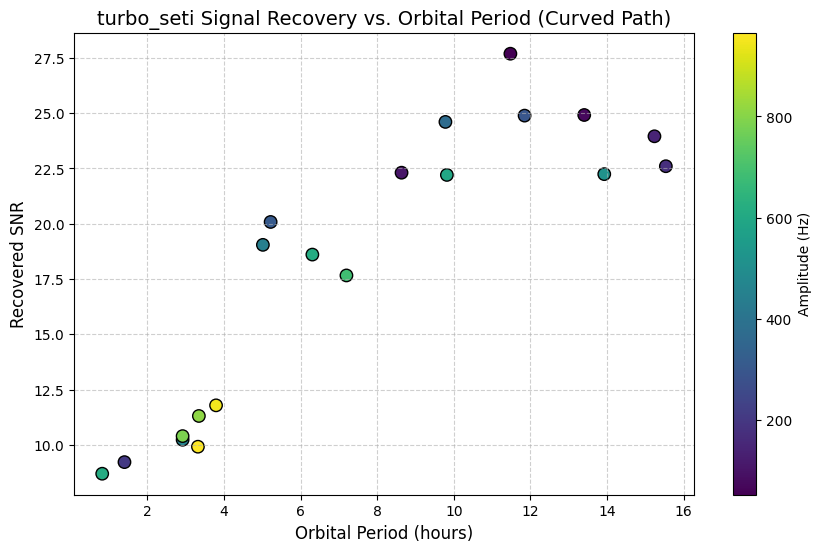

In [5]:
%matplotlib inline
import logging
logging.getLogger('turbo_seti').setLevel(logging.ERROR)
from turbo_seti import FindDoppler
from turbo_seti.find_event.find_event import read_dat
import tempfile
import os

num_simulations = 20
np.random.seed(42)

synthetic_periods_hr = np.random.uniform(0.5, 16.0, num_simulations) # increase period and amplited for further simulations to better acount for overall distribution of exoplanets
synthetic_amplitudes_hz = np.random.uniform(5.0, 1000.0, num_simulations)

total_obs_time = 30 * 60
tchans_count = 300
dt_step = total_obs_time / tchans_count

results = []

with tempfile.TemporaryDirectory() as tmpdir:
    for i in range(num_simulations):
        period_hr = synthetic_periods_hr[i]
        amplitude_hz = synthetic_amplitudes_hz[i]
        period_seconds = period_hr * 3600

        frame = stg.Frame(
            fchans=16384,
            tchans=tchans_count,
            df=2.7939677238464355 * u.Hz,
            dt=dt_step * u.s,
            fch1=8414.8056 * u.MHz
        )
        
        frame.add_noise(x_mean=10.0, x_std=2.0)

        signal_path = stg.sine_path(
            f_start=frame.get_frequency(index=8192),
            drift_rate=0.0 * u.Hz / u.s,
            period=period_seconds,
            amplitude=amplitude_hz * u.Hz
        )

        input_snr = 25.0
        frame.add_signal(
            signal_path,
            t_profile=stg.constant_t_profile(level=frame.get_intensity(snr=input_snr)),
            f_profile=stg.box_f_profile(width=frame.df),
            bp_profile=stg.constant_bp_profile(level=1.0)
        )

        filename = os.path.join(tmpdir, f"synthetic_sim_{i}.fil")
        frame.save_fil(filename)

        recovered_snr = 0.0  
        try:
            doppler_search = FindDoppler(
                filename, 
                max_drift=50.0, 
                snr=5.0, 
                out_dir=tmpdir, 
                n_coarse_chan=1, 
                log_level_int=40
            )
            doppler_search.search()
        except TypeError:
            pass

        dat_file_tmp = os.path.join(tmpdir, f"synthetic_sim_{i}.dat")
        
        if os.path.exists(dat_file_tmp):
            result_df = read_dat(dat_file_tmp)
            if result_df is not None and not result_df.empty:
                if 'SNR' in result_df.columns:
                    recovered_snr = result_df['SNR'].max()

        results.append({
            'period_hr': period_hr,
            'amplitude_hz': amplitude_hz,
            'recovered_snr': recovered_snr
        })

results_df = pd.DataFrame(results)

print("Results Summary DataFrame:")
print(results_df.head(10))

fig, ax = plt.subplots(figsize=(10, 6))
scatter = ax.scatter(
    results_df['period_hr'], 
    results_df['recovered_snr'], 
    c=results_df['amplitude_hz'], 
    cmap='viridis', 
    s=80, 
    edgecolors='k'
)
fig.colorbar(scatter, ax=ax, label='Amplitude (Hz)')
ax.set_xlabel('Orbital Period (hours)', fontsize=12)
ax.set_ylabel('Recovered SNR', fontsize=12)
ax.set_title('turbo_seti Signal Recovery vs. Orbital Period (Curved Path)', fontsize=14)
ax.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [1]:
c=results_df['amplitude_hz']
a = results_df['period_hr']
b = results_df['recovered_snr']
plt.scatter(a, c, c = b)
plt.show()

NameError: name 'results_df' is not defined